In [1]:
import os
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split


# ============================================================
# CONFIGURATION
# ============================================================

IMAGE_SIZE = (260, 260)
BATCH_SIZE = 32

MAX_SAMPLES = 6500

TEST_SIZE = 0.20
RANDOM_STATE = 42


# ============================================================
# HARD-CODE YOUR DATASET PATHS
# ============================================================

healthy_path = r"/kaggle/input/datasets/amrutdesh/unified-data-ver2/Unified_Data_2/Healthy"

unhealthy_path = r"/kaggle/input/datasets/amrutdesh/unified-data-ver2/Unified_Data_2/Unhealthy"


# ============================================================
# FUNCTION 1: LOAD IMAGE PATHS AND SPLIT DATA
# ============================================================

def load_data(
    healthy_path,
    unhealthy_path,
    max_samples=None,
    test_size=0.2,
    random_state=42
):

    image_paths = []
    labels = []

    # --------------------------------------------------------
    # Healthy images
    # --------------------------------------------------------

    healthy_files = [
        os.path.join(healthy_path, file)
        for file in os.listdir(healthy_path)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
        )
    ]

    rng = np.random.default_rng(random_state)
    rng.shuffle(healthy_files)

    if max_samples is not None:
        healthy_files = healthy_files[:max_samples]

    image_paths.extend(healthy_files)
    labels.extend([0] * len(healthy_files))


    # --------------------------------------------------------
    # Unhealthy images
    # --------------------------------------------------------

    unhealthy_files = [
        os.path.join(unhealthy_path, file)
        for file in os.listdir(unhealthy_path)
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
        )
    ]

    rng.shuffle(unhealthy_files)

    if max_samples is not None:
        unhealthy_files = unhealthy_files[:max_samples]

    image_paths.extend(unhealthy_files)
    labels.extend([1] * len(unhealthy_files))


    # --------------------------------------------------------
    # Convert to NumPy arrays
    # --------------------------------------------------------

    image_paths = np.array(image_paths)
    labels = np.array(labels)


    # --------------------------------------------------------
    # Dataset information
    # --------------------------------------------------------

    print("==========================================")
    print("DATASET INFORMATION")
    print("==========================================")

    print(f"Total images : {len(image_paths)}")
    print(f"Healthy      : {np.sum(labels == 0)}")
    print(f"Unhealthy    : {np.sum(labels == 1)}")


    # --------------------------------------------------------
    # Train / Test split
    # --------------------------------------------------------

    X_train, X_test, y_train, y_test = train_test_split(
        image_paths,
        labels,
        test_size=test_size,
        random_state=random_state,
        stratify=labels
    )


    print("\n==========================================")
    print("DATA SPLIT")
    print("==========================================")

    print(f"Training images : {len(X_train)}")
    print(f"Testing images  : {len(X_test)}")


    return X_train, X_test, y_train, y_test


# ============================================================
# FUNCTION 2: CREATE TF.DATA DATASET
# ============================================================

def create_dataset(
    image_paths,
    labels,
    image_size=(260, 260),
    batch_size=32,
    shuffle=False
):

    def load_image(path, label):

        # Read image from disk
        image = tf.io.read_file(path)

        # Decode image
        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        # Ensure TensorFlow knows the image shape
        image.set_shape([None, None, 3])

        # ----------------------------------------------------
        # Resize 224 × 224 → 260 × 260
        # ----------------------------------------------------

        image = tf.image.resize(
            image,
            image_size
        )

        # Convert to float32
        image = tf.cast(
            image,
            tf.float32
        )

        return image, label


    # Create dataset from paths
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )


    # Shuffle only training dataset
    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            reshuffle_each_iteration=True
        )


    # Load images when required
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )


    # Create batches
    dataset = dataset.batch(
        batch_size
    )


    # Prefetch next batch while model trains
    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )


    return dataset


# ============================================================
# RUN STAGE 1
# ============================================================

X_train, X_test, y_train, y_test = load_data(
    healthy_path=healthy_path,
    unhealthy_path=unhealthy_path,
    max_samples=MAX_SAMPLES,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)


# ============================================================
# CREATE TRAINING DATASET
# ============================================================

train_dataset = create_dataset(
    X_train,
    y_train,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)


# ============================================================
# CREATE TEST DATASET
# ============================================================

test_dataset = create_dataset(
    X_test,
    y_test,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("\n==========================================")
print("DATA PIPELINE READY")
print("==========================================")

print("Image size :", IMAGE_SIZE)
print("Batch size :", BATCH_SIZE)

DATASET INFORMATION
Total images : 13000
Healthy      : 6500
Unhealthy    : 6500

DATA SPLIT
Training images : 10400
Testing images  : 2600

DATA PIPELINE READY
Image size : (260, 260)
Batch size : 32


I0000 00:00:1787751583.247313      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787751583.250451      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB2


def build_efficientnet_b2_stage1(
    input_shape=(260, 260, 3),
    dropout_rate=0.3,
    learning_rate=1e-3
):
    """
    Stage 1:
    EfficientNetB2 is used as a frozen feature extractor.

    Only the classification head is trainable.

    Classes:
        0 -> Healthy
        1 -> Unhealthy
    """

    # ========================================================
    # PRETRAINED EFFICIENTNETB2
    # ========================================================

    base_model = EfficientNetB2(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )


    # ========================================================
    # FREEZE ENTIRE EFFICIENTNET
    # ========================================================

    base_model.trainable = False


    # ========================================================
    # CLASSIFICATION HEAD
    # ========================================================

    inputs = layers.Input(
        shape=input_shape
    )

    # Extract features
    x = base_model(
        inputs,
        training=False
    )

    # Convert feature maps into feature vector
    x = layers.GlobalAveragePooling2D()(x)

    # Prevent overfitting
    x = layers.Dropout(
        dropout_rate
    )(x)

    # Binary classification
    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)


    # ========================================================
    # COMPLETE MODEL
    # ========================================================

    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )


    return model

In [3]:
model = build_efficientnet_b2_stage1(
    input_shape=(260, 260, 3),
    dropout_rate=0.3,
    learning_rate=1e-3
)

model.summary()

print("Total parameters     :", model.count_params())
print("Trainable parameters :", 
      np.sum([
          tf.keras.backend.count_params(w)
          for w in model.trainable_weights
      ]))

31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb2 (Functional)     │ (None, 9, 9, 1408)     │     7,768,569 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1408)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,409 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,769,978 (29.64 MB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 7,768,569 (29.63 MB)

Total parameters     : 7769978
Trainable parameters : 1409


In [4]:
history_stage1 = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10
)

Epoch 1/10


2026-08-26 13:41:01.032676: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:41:01.182227: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:41:01.570556: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:41:01.716811: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:41:02.612558: E external/local_xla/xla/stream_

325/325 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.7745 - loss: 0.4967

2026-08-26 13:41:59.794945: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:41:59.932225: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:42:00.249307: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:42:00.393931: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:42:01.238394: E external/local_xla/xla/stream_

325/325 ━━━━━━━━━━━━━━━━━━━━ 96s 161ms/step - accuracy: 0.8199 - loss: 0.4279 - val_accuracy: 0.8642 - val_loss: 0.3343
Epoch 2/10
325/325 ━━━━━━━━━━━━━━━━━━━━ 29s 89ms/step - accuracy: 0.8688 - loss: 0.3278 - val_accuracy: 0.8969 - val_loss: 0.2789
Epoch 3/10
325/325 ━━━━━━━━━━━━━━━━━━━━ 29s 90ms/step - accuracy: 0.8742 - loss: 0.2997 - val_accuracy: 0.8919 - val_loss: 0.2607
Epoch 4/10
325/325 ━━━━━━━━━━━━━━━━━━━━ 29s 88ms/step - accuracy: 0.8844 - loss: 0.2833 - val_accuracy: 0.8858 - val_loss: 0.2574
Epoch 5/10
325/325 ━━━━━━━━━━━━━━━━━━━━ 29s 89ms/step - accuracy: 0.8794 - loss: 0.2761 - val_accuracy: 0.9073 - val_loss: 0.2365
Epoch 6/10
325/325 ━━━━━━━━━━━━━━━━━━━━ 29s 89ms/step - accuracy: 0.8809 - loss: 0.2744 - val_accuracy: 0.9085 - val_loss: 0.2317
Epoch 7/10
325/325 ━━━━━━━━━━━━━━━━━━━━ 29s 89ms/step - accuracy: 0.8872 - loss: 0.2659 - val_accuracy: 0.9035 - val_loss: 0.2276
Epoch 8/10
325/325 ━━━━━━━━━━━━━━━━━━━━ 29s 89ms/step - accuracy: 0.8885 - loss: 0.2636 - val_accura

In [5]:
model.save_weights("efficientnet4500_b2_stage1.weights.h5")

In [6]:
# ============================================================
# STAGE 2: PARTIAL FINE-TUNING
# ============================================================

# Find the EfficientNetB2 base model
base_model = None

for layer in model.layers:

    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break


print("Base model:", base_model.name)

Base model: efficientnetb2


In [7]:
# ============================================================
# UNFREEZE LAST 30 LAYERS
# ============================================================

FINE_TUNE_LAYERS = 30

# First make the whole backbone trainable
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-FINE_TUNE_LAYERS]:

    layer.trainable = False


# Keep Batch Normalization layers frozen
for layer in base_model.layers[-FINE_TUNE_LAYERS:]:

    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

In [8]:
total_params = model.count_params()

trainable_params = np.sum([
    tf.keras.backend.count_params(weight)
    for weight in model.trainable_weights
])

non_trainable_params = (
    total_params - trainable_params
)

print("\n======================================")
print("FINE-TUNING CONFIGURATION")
print("======================================")

print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")
print(f"Non-trainable params  : {non_trainable_params:,}")
print(f"Fine-tuning layers    : {FINE_TUNE_LAYERS}")


FINE-TUNING CONFIGURATION
Total parameters      : 7,769,978
Trainable parameters  : 2,958,413
Non-trainable params  : 4,811,565
Fine-tuning layers    : 30


In [9]:
# ============================================================
# RECOMPILE FOR FINE-TUNING
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [10]:
# ============================================================
# TRAIN STAGE 2
# ============================================================

history_stage2 = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=40
)

Epoch 1/40


2026-08-26 13:48:08.665037: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:48:08.810179: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:48:09.498614: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:48:09.636918: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 13:48:09.929829: E external/local_xla/xla/stream_

325/325 ━━━━━━━━━━━━━━━━━━━━ 89s 156ms/step - accuracy: 0.8937 - loss: 0.2480 - val_accuracy: 0.9150 - val_loss: 0.2011
Epoch 2/40
325/325 ━━━━━━━━━━━━━━━━━━━━ 34s 106ms/step - accuracy: 0.9014 - loss: 0.2329 - val_accuracy: 0.9200 - val_loss: 0.1879
Epoch 3/40
325/325 ━━━━━━━━━━━━━━━━━━━━ 34s 104ms/step - accuracy: 0.9047 - loss: 0.2209 - val_accuracy: 0.9292 - val_loss: 0.1779
Epoch 4/40
325/325 ━━━━━━━━━━━━━━━━━━━━ 34s 103ms/step - accuracy: 0.9122 - loss: 0.2063 - val_accuracy: 0.9327 - val_loss: 0.1683
Epoch 5/40
325/325 ━━━━━━━━━━━━━━━━━━━━ 34s 104ms/step - accuracy: 0.9171 - loss: 0.1964 - val_accuracy: 0.9365 - val_loss: 0.1588
Epoch 6/40
325/325 ━━━━━━━━━━━━━━━━━━━━ 34s 104ms/step - accuracy: 0.9209 - loss: 0.1889 - val_accuracy: 0.9350 - val_loss: 0.1518
Epoch 7/40
325/325 ━━━━━━━━━━━━━━━━━━━━ 34s 104ms/step - accuracy: 0.9230 - loss: 0.1856 - val_accuracy: 0.9396 - val_loss: 0.1463
Epoch 8/40
325/325 ━━━━━━━━━━━━━━━━━━━━ 34s 104ms/step - accuracy: 0.9257 - loss: 0.1769 - val

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [12]:
def evaluate_stage(
    model,
    dataset,
    y_true,
    stage_name
):
    """
    Evaluates one training stage.

    Returns:
        Dictionary containing all major metrics.
    """

    # ========================================================
    # MODEL LOSS AND ACCURACY
    # ========================================================

    loss, accuracy = model.evaluate(
        dataset,
        verbose=0
    )


    # ========================================================
    # PREDICTIONS
    # ========================================================

    probabilities = model.predict(
        dataset,
        verbose=0
    ).flatten()

    y_pred = (
        probabilities >= 0.5
    ).astype(int)


    # ========================================================
    # METRICS
    # ========================================================

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )


    # ========================================================
    # CLASSIFICATION REPORT
    # ========================================================

    print("\n")
    print("=" * 60)
    print(stage_name)
    print("=" * 60)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=[
                "Healthy",
                "Unhealthy"
            ],
            digits=4,
            zero_division=0
        )
    )


    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(
        figsize=(6, 5)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "Healthy",
            "Unhealthy"
        ],
        yticklabels=[
            "Healthy",
            "Unhealthy"
        ]
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(
        f"{stage_name} - Confusion Matrix"
    )

    plt.show()


    return {
        "stage": stage_name,
        "loss": loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "y_pred": y_pred,
        "probabilities": probabilities,
        "confusion_matrix": cm
    }

In [13]:
stage1_model = build_efficientnet_b2_stage1(
    input_shape=(260, 260, 3),
    dropout_rate=0.3,
    learning_rate=1e-3
)

In [14]:
stage1_model.load_weights(
    "efficientnet4500_b2_stage1.weights.h5"
)

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))




Stage 1 - Feature Extraction
Accuracy  : 0.6235
Precision : 0.7913
Recall    : 0.3354
F1-score  : 0.4711

Classification Report:

              precision    recall  f1-score   support

     Healthy     0.5783    0.9115    0.7077      1300
   Unhealthy     0.7913    0.3354    0.4711      1300

    accuracy                         0.6235      2600
   macro avg     0.6848    0.6235    0.5894      2600
weighted avg     0.6848    0.6235    0.5894      2600



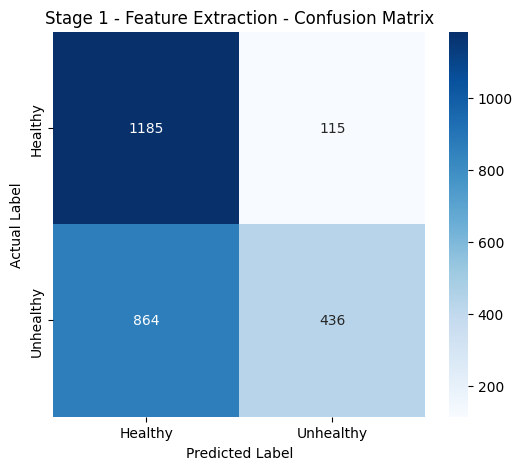

In [16]:
stage1_results = evaluate_stage(
    model=stage1_model,
    dataset=test_dataset,
    y_true=y_test,
    stage_name="Stage 1 - Feature Extraction"
)



Stage 2 - Partial Fine-Tuning
Accuracy  : 0.9623
Precision : 0.9740
Recall    : 0.9500
F1-score  : 0.9618

Classification Report:

              precision    recall  f1-score   support

     Healthy     0.9512    0.9746    0.9628      1300
   Unhealthy     0.9740    0.9500    0.9618      1300

    accuracy                         0.9623      2600
   macro avg     0.9626    0.9623    0.9623      2600
weighted avg     0.9626    0.9623    0.9623      2600



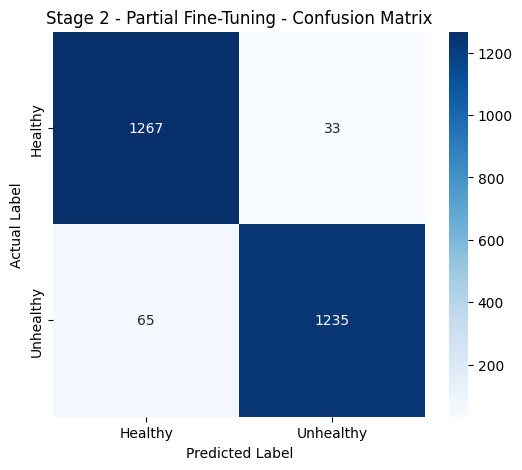

In [18]:
stage2_results = evaluate_stage(
    model=model,
    dataset=test_dataset,
    y_true=y_test,
    stage_name="Stage 2 - Partial Fine-Tuning"
)

In [17]:
comparison = pd.DataFrame({

    "Stage": [
        "Stage 1 - Feature Extraction",
        "Stage 2 - Partial Fine-Tuning"
    ],

    "Accuracy": [
        stage1_results["accuracy"],
        stage2_results["accuracy"]
    ],

    "Precision": [
        stage1_results["precision"],
        stage2_results["precision"]
    ],

    "Recall": [
        stage1_results["recall"],
        stage2_results["recall"]
    ],

    "F1-Score": [
        stage1_results["f1_score"],
        stage2_results["f1_score"]
    ]

})


print("\n==============================================")
print("UNIFIED MODEL COMPARISON")
print("==============================================")

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


UNIFIED MODEL COMPARISON
                        Stage  Accuracy  Precision  Recall  F1-Score
 Stage 1 - Feature Extraction    0.6235     0.7913  0.3354    0.4711
Stage 2 - Partial Fine-Tuning    0.9623     0.9740  0.9500    0.9618


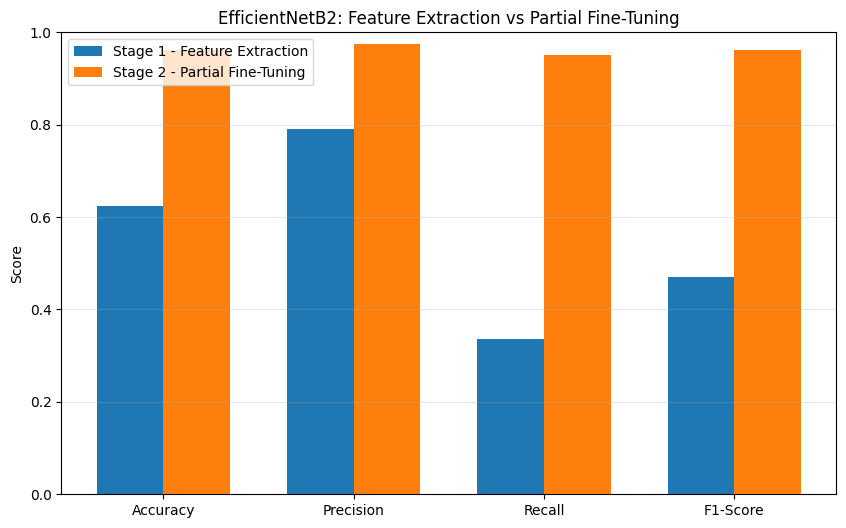

In [19]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

stage1_values = [
    stage1_results["accuracy"],
    stage1_results["precision"],
    stage1_results["recall"],
    stage1_results["f1_score"]
]

stage2_values = [
    stage2_results["accuracy"],
    stage2_results["precision"],
    stage2_results["recall"],
    stage2_results["f1_score"]
]


x = np.arange(len(metrics))
width = 0.35


plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    stage1_values,
    width,
    label="Stage 1 - Feature Extraction"
)

plt.bar(
    x + width / 2,
    stage2_values,
    width,
    label="Stage 2 - Partial Fine-Tuning"
)


plt.xticks(
    x,
    metrics
)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.title(
    "EfficientNetB2: Feature Extraction vs Partial Fine-Tuning"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

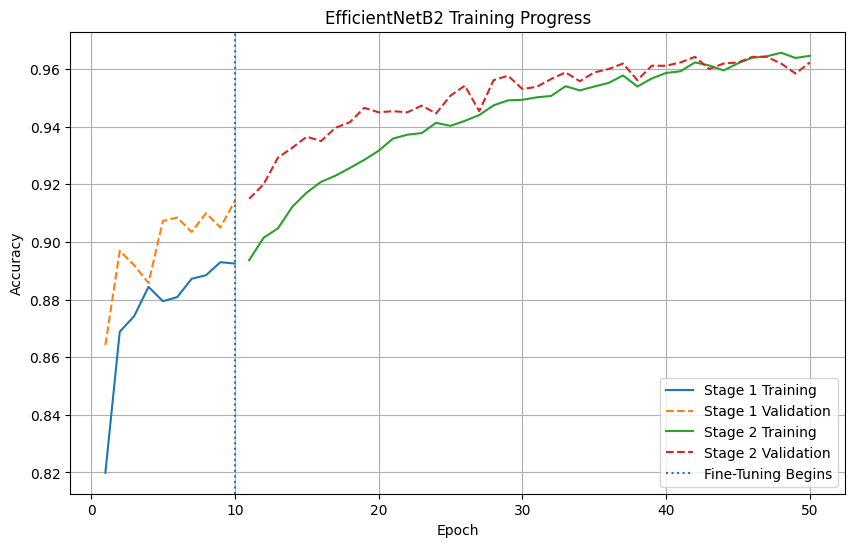

In [20]:
stage1_epochs = range(
    1,
    len(history_stage1.history["accuracy"]) + 1
)

stage2_epochs = range(
    len(history_stage1.history["accuracy"]) + 1,
    len(history_stage1.history["accuracy"])
    + len(history_stage2.history["accuracy"])
    + 1
)


plt.figure(figsize=(10, 6))


# Stage 1 training
plt.plot(
    stage1_epochs,
    history_stage1.history["accuracy"],
    label="Stage 1 Training"
)


# Stage 1 validation
plt.plot(
    stage1_epochs,
    history_stage1.history["val_accuracy"],
    linestyle="--",
    label="Stage 1 Validation"
)


# Stage 2 training
plt.plot(
    stage2_epochs,
    history_stage2.history["accuracy"],
    label="Stage 2 Training"
)


# Stage 2 validation
plt.plot(
    stage2_epochs,
    history_stage2.history["val_accuracy"],
    linestyle="--",
    label="Stage 2 Validation"
)


# Mark transition between stages
plt.axvline(
    x=len(history_stage1.history["accuracy"]),
    linestyle=":",
    label="Fine-Tuning Begins"
)


plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "EfficientNetB2 Training Progress"
)

plt.legend()

plt.grid(True)

plt.show()

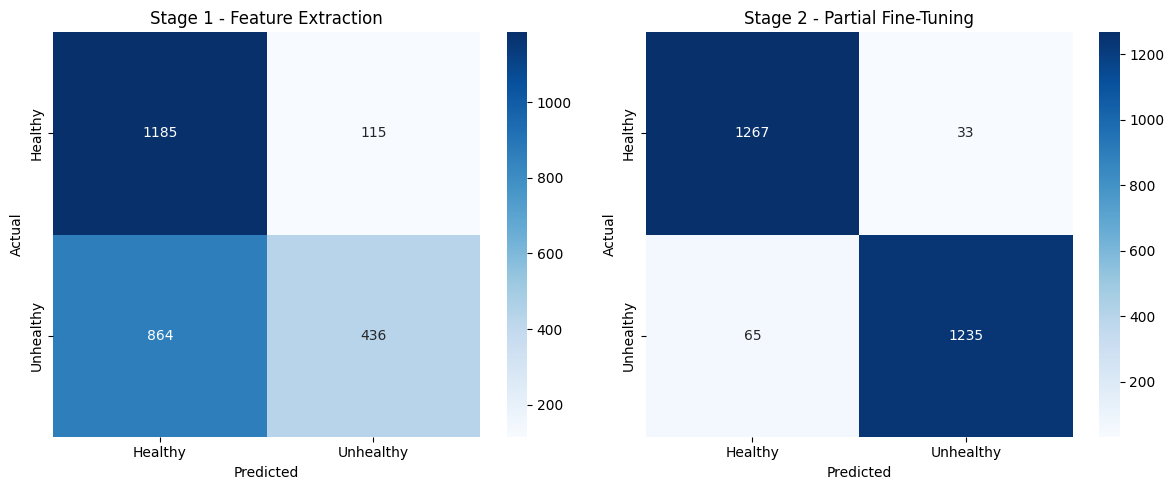

In [21]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


# ------------------------------------------------------------
# Stage 1
# ------------------------------------------------------------

sns.heatmap(
    stage1_results["confusion_matrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Unhealthy"],
    yticklabels=["Healthy", "Unhealthy"],
    ax=axes[0]
)

axes[0].set_title(
    "Stage 1 - Feature Extraction"
)

axes[0].set_xlabel(
    "Predicted"
)

axes[0].set_ylabel(
    "Actual"
)


# ------------------------------------------------------------
# Stage 2
# ------------------------------------------------------------

sns.heatmap(
    stage2_results["confusion_matrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Unhealthy"],
    yticklabels=["Healthy", "Unhealthy"],
    ax=axes[1]
)

axes[1].set_title(
    "Stage 2 - Partial Fine-Tuning"
)

axes[1].set_xlabel(
    "Predicted"
)

axes[1].set_ylabel(
    "Actual"
)


plt.tight_layout()

plt.show()

In [22]:
model.save("efficientnet_model_PF_4500_B2.keras")

MODEL INFORMATION
Model input shape: (None, 260, 260, 3)
Model output shape: (None, 1)
Expected image size: 260 x 260

DATASET INFORMATION
Healthy images   : 595
Unhealthy images : 591
Total images     : 1186

RUNNING TEST DATASET

Testing Healthy images...


2026-08-26 14:18:09.814573: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 14:18:09.947529: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 14:18:10.254757: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 14:18:10.393301: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-26 14:18:10.531967: E external/local_xla/xla/stream_

Testing Unhealthy images...

OVERALL METRICS
Accuracy  : 0.9089
Precision : 0.9086
Recall    : 0.9086
F1 Score  : 0.9086
ROC-AUC   : 0.9645
PR-AUC    : 0.9532

CONFUSION MATRIX
[[541  54]
 [ 54 537]]

                 Predicted
              Healthy  Unhealthy
Actual Healthy     541        54
Actual Unhealthy    54       537

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy       0.91      0.91      0.91       595
   Unhealthy       0.91      0.91      0.91       591

    accuracy                           0.91      1186
   macro avg       0.91      0.91      0.91      1186
weighted avg       0.91      0.91      0.91      1186


PREDICTION DISTRIBUTION
Predicted Healthy   : 595
Predicted Unhealthy : 591

PROBABILITY STATISTICS

Healthy images:
Mean probability     : 0.1061
Minimum probability  : 0.0000
Maximum probability  : 0.9999

Unhealthy images:
Mean probability     : 0.8556
Minimum probability  : 0.0172
Maximum probability  : 1.0000


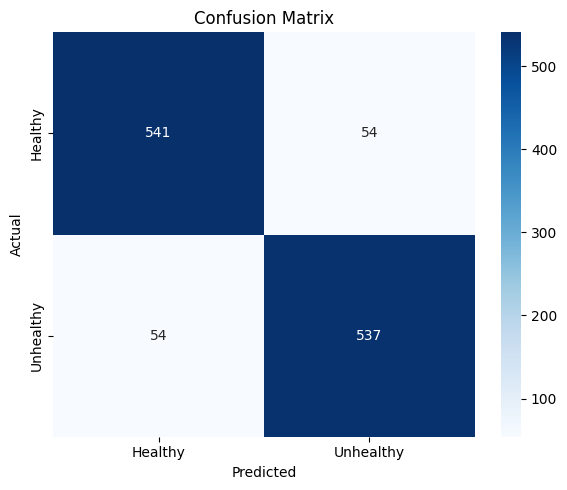

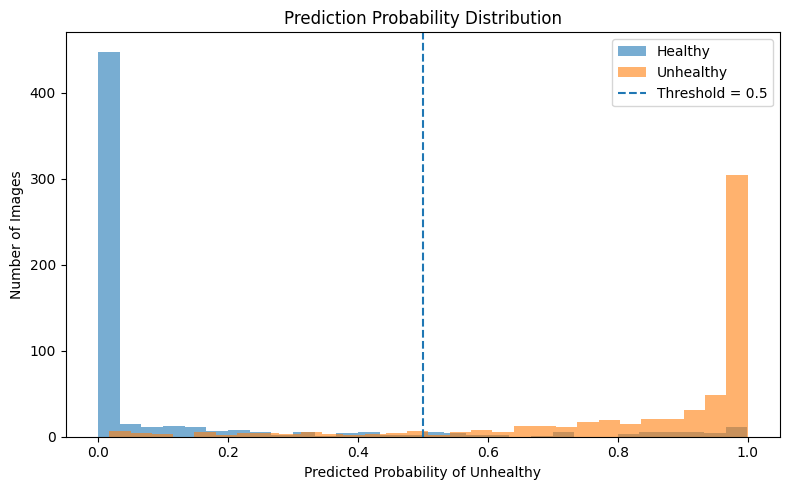

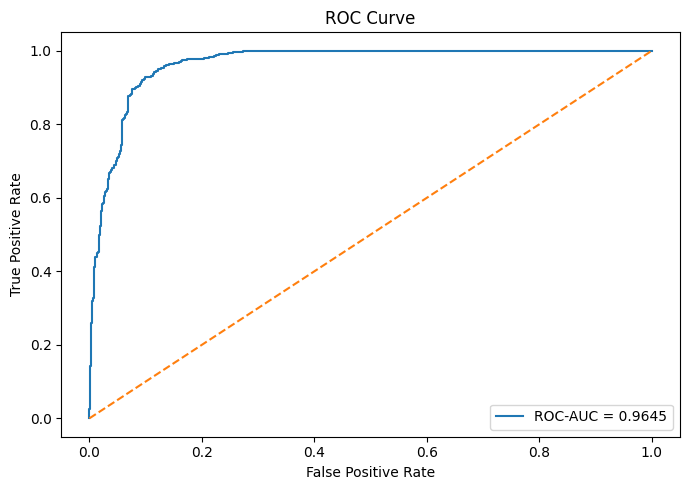

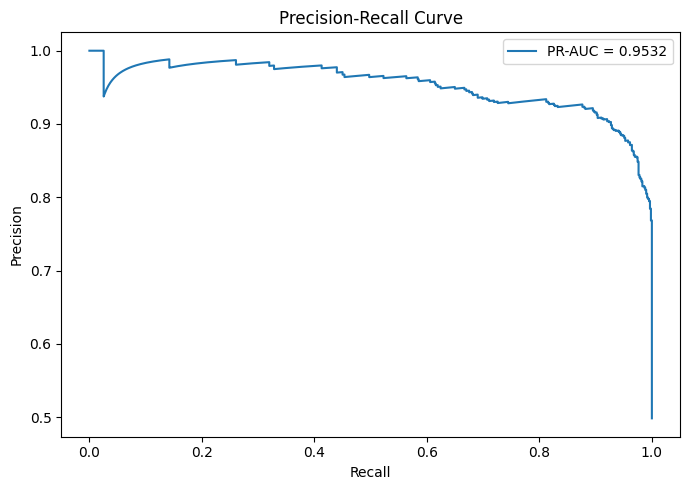


SINGLE IMAGE PREDICTION

Single image does not exist:
/kaggle/input/datasets/amrutdesh/unified/Unified_Data/Unhealthy/Unhealthy_Images_100.jpg


In [23]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)


# ============================================================
# USER SETTINGS
# ============================================================


TEST_DIR = "/kaggle/input/datasets/amrutdesh/ext2-data/EXT2"

HEALTHY_DIR = os.path.join(TEST_DIR, "Healthy")
UNHEALTHY_DIR = os.path.join(TEST_DIR, "Unhealthy")


# ------------------------------------------------------------
# Single image to test
# ------------------------------------------------------------

SINGLE_IMAGE_PATH = r"/kaggle/input/datasets/amrutdesh/unified/Unified_Data/Unhealthy/Unhealthy_Images_100.jpg"


# ------------------------------------------------------------
# Classification threshold
# ------------------------------------------------------------

THRESHOLD = 0.5


# ============================================================
# 1. GET MODEL INPUT SIZE
# ============================================================

input_shape = model.input_shape

print("=" * 70)
print("MODEL INFORMATION")
print("=" * 70)

print("Model input shape:", input_shape)
print("Model output shape:", model.output_shape)

# Usually:
# (None, 224, 224, 3) -> EfficientNet-B0
# (None, 260, 260, 3) -> EfficientNet-B2

IMG_HEIGHT = input_shape[1]
IMG_WIDTH = input_shape[2]

print(f"Expected image size: {IMG_WIDTH} x {IMG_HEIGHT}")


# ============================================================
# 2. FIND IMAGES
# ============================================================

VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
)


def get_images(folder):

    images = []

    if not os.path.exists(folder):
        print(f"\nWARNING: Folder does not exist:")
        print(folder)
        return images

    for filename in os.listdir(folder):

        if filename.lower().endswith(VALID_EXTENSIONS):

            images.append(
                os.path.join(folder, filename)
            )

    return images


healthy_images = get_images(HEALTHY_DIR)
unhealthy_images = get_images(UNHEALTHY_DIR)


print("\n" + "=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Healthy images   :", len(healthy_images))
print("Unhealthy images :", len(unhealthy_images))
print("Total images     :", len(healthy_images) + len(unhealthy_images))


# ============================================================
# 3. IMAGE PREPROCESSING
# ============================================================

def preprocess_image(image_path):

    image = Image.open(image_path).convert("RGB")

    # Resize to model input size
    image = image.resize(
        (IMG_WIDTH, IMG_HEIGHT)
    )

    image = np.array(image).astype(np.float32)

    # Add batch dimension
    image = np.expand_dims(image, axis=0)

    return image


# ============================================================
# 4. GET MODEL PROBABILITY
# ============================================================

def get_probability(image_path):

    image = preprocess_image(image_path)

    prediction = model.predict(
        image,
        verbose=0
    )

    # Binary sigmoid model
    probability = float(
        np.squeeze(prediction)
    )

    return probability


# ============================================================
# 5. EVALUATE COMPLETE TEST DATASET
# ============================================================

y_true = []
y_probability = []

print("\n" + "=" * 70)
print("RUNNING TEST DATASET")
print("=" * 70)


# ------------------------------------------------------------
# Healthy = 0
# ------------------------------------------------------------

print("\nTesting Healthy images...")

for i, image_path in enumerate(healthy_images):

    try:

        probability = get_probability(image_path)

        y_true.append(0)
        y_probability.append(probability)

    except Exception as e:

        print(
            f"Error processing {image_path}: {e}"
        )


# ------------------------------------------------------------
# Unhealthy = 1
# ------------------------------------------------------------

print("Testing Unhealthy images...")

for i, image_path in enumerate(unhealthy_images):

    try:

        probability = get_probability(image_path)

        y_true.append(1)
        y_probability.append(probability)

    except Exception as e:

        print(
            f"Error processing {image_path}: {e}"
        )


y_true = np.array(y_true)
y_probability = np.array(y_probability)


# ============================================================
# 6. CONVERT PROBABILITY TO CLASS
# ============================================================

y_pred = (
    y_probability >= THRESHOLD
).astype(int)


# ============================================================
# 7. BASIC METRICS
# ============================================================

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)


print("\n" + "=" * 70)
print("OVERALL METRICS")
print("=" * 70)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")


# ============================================================
# 8. ROC-AUC
# ============================================================

if len(np.unique(y_true)) == 2:

    roc_auc = roc_auc_score(
        y_true,
        y_probability
    )

    print(f"ROC-AUC   : {roc_auc:.4f}")


# ============================================================
# 9. PR-AUC
# ============================================================

if len(np.unique(y_true)) == 2:

    pr_auc = average_precision_score(
        y_true,
        y_probability
    )

    print(f"PR-AUC    : {pr_auc:.4f}")


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)

print("\n                 Predicted")
print("              Healthy  Unhealthy")
print(
    f"Actual Healthy   {cm[0,0]:5d}     {cm[0,1]:5d}"
)
print(
    f"Actual Unhealthy {cm[1,0]:5d}     {cm[1,1]:5d}"
)


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Healthy",
            "Unhealthy"
        ],
        zero_division=0
    )
)


# ============================================================
# 12. IMPORTANT:
#    CHECK HOW MANY IMAGES ARE PREDICTED AS EACH CLASS
# ============================================================

healthy_predictions = np.sum(
    y_pred == 0
)

unhealthy_predictions = np.sum(
    y_pred == 1
)

print("\n" + "=" * 70)
print("PREDICTION DISTRIBUTION")
print("=" * 70)

print(
    "Predicted Healthy   :",
    healthy_predictions
)

print(
    "Predicted Unhealthy :",
    unhealthy_predictions
)


# ============================================================
# 13. LOOK AT PROBABILITY DISTRIBUTION
# ============================================================

healthy_probabilities = y_probability[
    y_true == 0
]

unhealthy_probabilities = y_probability[
    y_true == 1
]


print("\n" + "=" * 70)
print("PROBABILITY STATISTICS")
print("=" * 70)

print("\nHealthy images:")

print(
    f"Mean probability     : "
    f"{np.mean(healthy_probabilities):.4f}"
)

print(
    f"Minimum probability  : "
    f"{np.min(healthy_probabilities):.4f}"
)

print(
    f"Maximum probability  : "
    f"{np.max(healthy_probabilities):.4f}"
)


print("\nUnhealthy images:")

print(
    f"Mean probability     : "
    f"{np.mean(unhealthy_probabilities):.4f}"
)

print(
    f"Minimum probability  : "
    f"{np.min(unhealthy_probabilities):.4f}"
)

print(
    f"Maximum probability  : "
    f"{np.max(unhealthy_probabilities):.4f}"
)


# ============================================================
# 14. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Healthy",
        "Unhealthy"
    ],
    yticklabels=[
        "Healthy",
        "Unhealthy"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()


# ============================================================
# 15. PROBABILITY DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    healthy_probabilities,
    bins=30,
    alpha=0.6,
    label="Healthy"
)

plt.hist(
    unhealthy_probabilities,
    bins=30,
    alpha=0.6,
    label="Unhealthy"
)

plt.axvline(
    THRESHOLD,
    linestyle="--",
    label=f"Threshold = {THRESHOLD}"
)

plt.xlabel(
    "Predicted Probability of Unhealthy"
)

plt.ylabel("Number of Images")

plt.title(
    "Prediction Probability Distribution"
)

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 16. ROC CURVE
# ============================================================

if len(np.unique(y_true)) == 2:

    fpr, tpr, _ = roc_curve(
        y_true,
        y_probability
    )

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {roc_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title("ROC Curve")

    plt.legend()

    plt.tight_layout()
    plt.show()


# ============================================================
# 17. PRECISION-RECALL CURVE
# ============================================================

if len(np.unique(y_true)) == 2:

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_true,
            y_probability
        )
    )

    plt.figure(figsize=(7, 5))

    plt.plot(
        recall_curve,
        precision_curve,
        label=f"PR-AUC = {pr_auc:.4f}"
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")

    plt.title(
        "Precision-Recall Curve"
    )

    plt.legend()

    plt.tight_layout()
    plt.show()


# ============================================================
# 18. SINGLE IMAGE PREDICTION
# ============================================================

print("\n" + "=" * 70)
print("SINGLE IMAGE PREDICTION")
print("=" * 70)


if os.path.exists(SINGLE_IMAGE_PATH):

    probability = get_probability(
        SINGLE_IMAGE_PATH
    )

    predicted_class = (
        1
        if probability >= THRESHOLD
        else 0
    )

    if predicted_class == 1:
        label = "UNHEALTHY"
    else:
        label = "HEALTHY"

    print("\nImage:")
    print(SINGLE_IMAGE_PATH)

    print(
        f"\nProbability of Unhealthy: "
        f"{probability:.6f}"
    )

    print(
        f"Probability of Healthy: "
        f"{1 - probability:.6f}"
    )

    print(
        f"\nPredicted class: {predicted_class}"
    )

    print(
        f"Predicted label: {label}"
    )

else:

    print(
        "\nSingle image does not exist:"
    )

    print(SINGLE_IMAGE_PATH)

In [25]:
model.save("/kaggle/working/crop_classifier.keras")